<a href="https://colab.research.google.com/github/Aigulya0/ml-practice/blob/main/Practice_02_Full_EDA_Wine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

%pip install pandas numpy matplotlib seaborn scikit-learn


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Датасет успешно загружен!")
print("Размер:", df.shape)

display(df.head())


Датасет успешно загружен!
Размер: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:

print("1. Размер таблицы:")
print(df.shape)

print("\n2. Названия и типы столбцов:")
print(df.dtypes)

print("\n3. Пропущенные значения:")
print(df.isnull().sum())

print("\n4. Основная статистика:")
display(df.describe())

print("\n5. Дубликаты:")
print(df.duplicated().sum())


1. Размер таблицы:
(1599, 12)

2. Названия и типы столбцов:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

3. Пропущенные значения:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

4. Основная статистика:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000



5. Дубликаты:
240


In [4]:

numeric_features = df.drop(columns=["quality"]).columns.tolist()
categorical_features = ["quality"]

print("Числовые признаки:")
print(numeric_features)

print("\nКатегориальные признаки:")
print(categorical_features)

print("\nТипы признаков:")
for col in df.columns:
    if col == "quality":
        print(col, "- целевой, порядковый")
    else:
        print(col, "- числовой")


Числовые признаки:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Категориальные признаки:
['quality']

Типы признаков:
fixed acidity - числовой
volatile acidity - числовой
citric acid - числовой
residual sugar - числовой
chlorides - числовой
free sulfur dioxide - числовой
total sulfur dioxide - числовой
density - числовой
pH - числовой
sulphates - числовой
alcohol - числовой
quality - целевой, порядковый


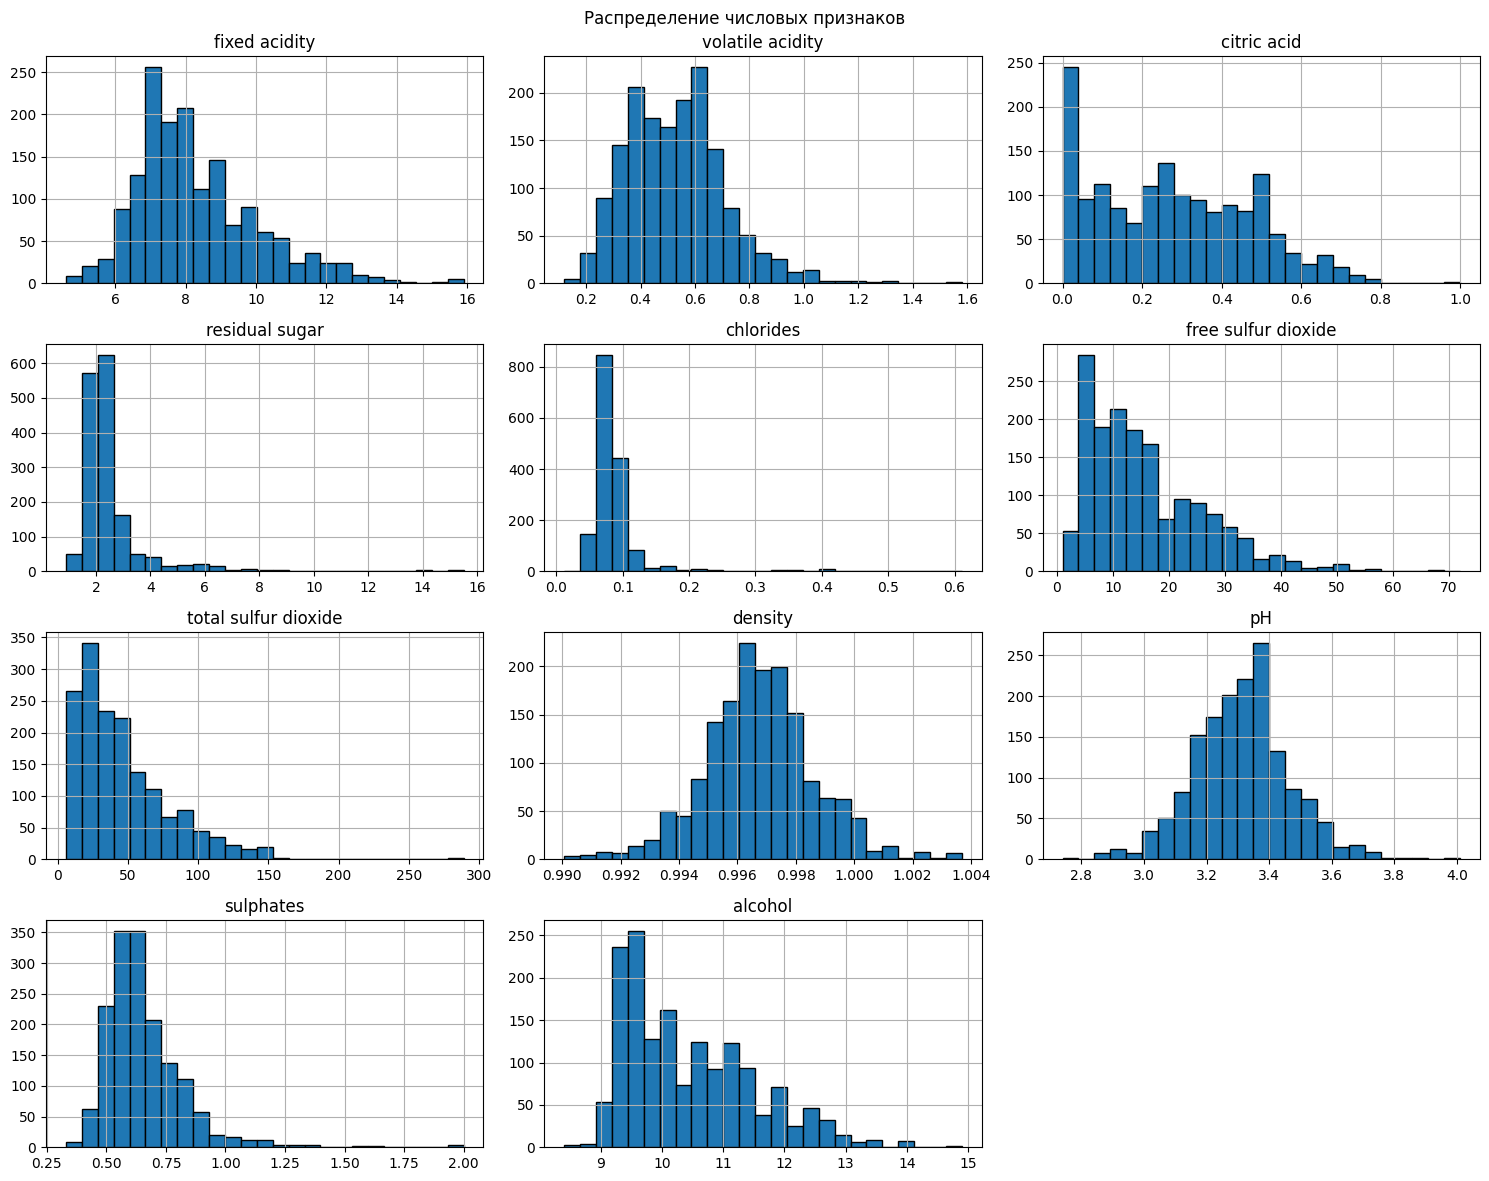

In [5]:

df[numeric_features].hist(
    figsize=(15, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Распределение числовых признаков")
plt.tight_layout()
plt.show()


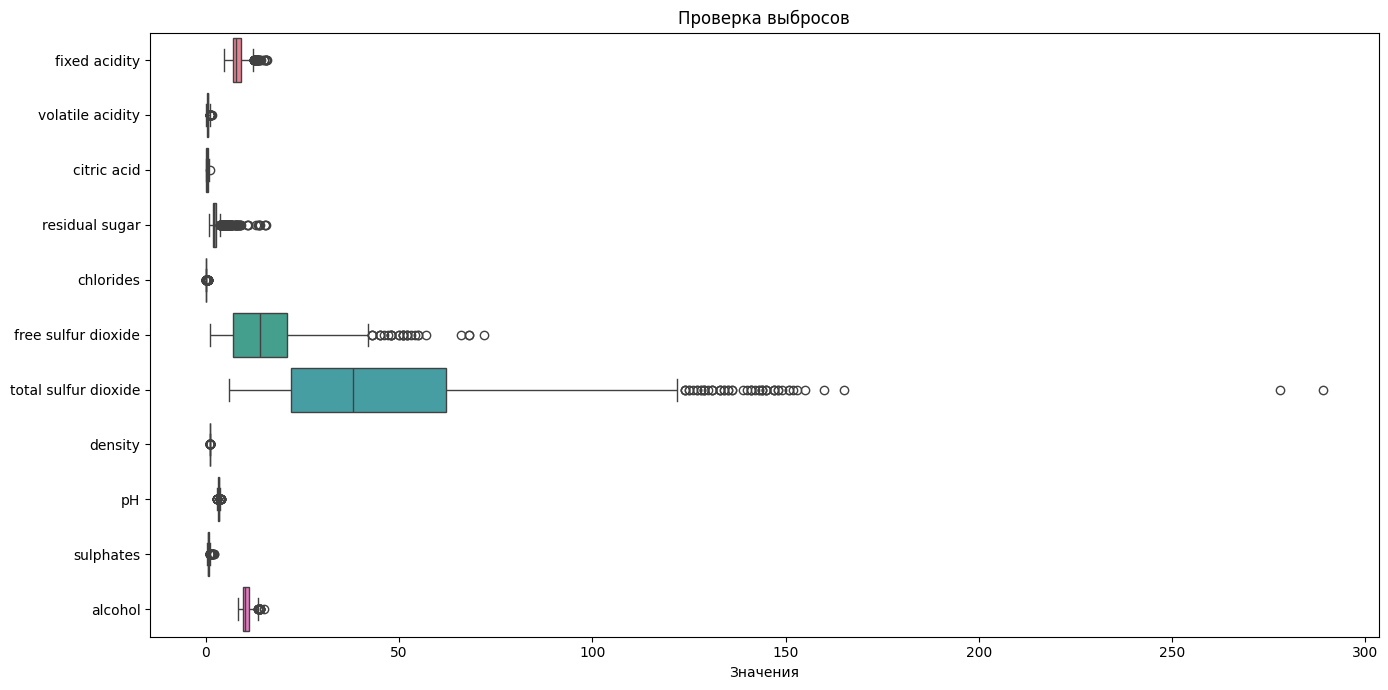

In [6]:

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[numeric_features], orient="h")

plt.title("Проверка выбросов")
plt.xlabel("Значения")
plt.tight_layout()
plt.show()


In [7]:

outliers = {}

for col in numeric_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outliers[col] = count

display(pd.DataFrame.from_dict(
    outliers,
    orient="index",
    columns=["Количество выбросов"]
))


,Количество выбросов
fixed acidity,49
volatile acidity,19
citric acid,1
residual sugar,155
chlorides,112
free sulfur dioxide,30
total sulfur dioxide,55
density,45
pH,35
sulphates,59


Частота оценок качества:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Процент каждой категории:
quality
3     0.625391
4     3.314572
5    42.589118
6    39.899937
7    12.445278
8     1.125704
Name: proportion, dtype: float64


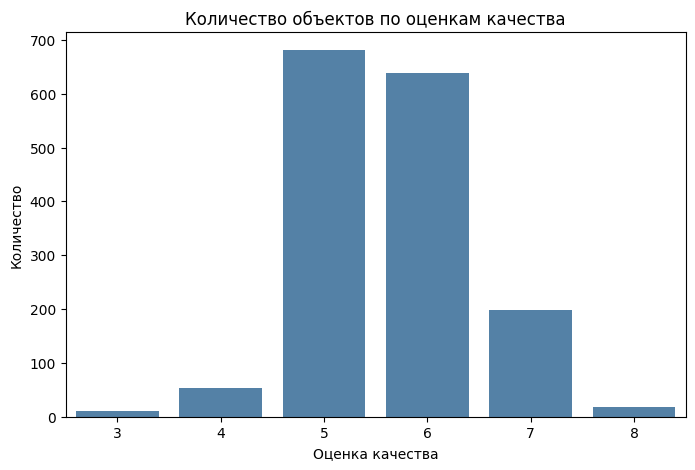

In [8]:

print("Частота оценок качества:")
print(df["quality"].value_counts().sort_index())

print("\nПроцент каждой категории:")
print(
    df["quality"].value_counts(normalize=True)
    .sort_index() * 100
)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality", color="steelblue")

plt.title("Количество объектов по оценкам качества")
plt.xlabel("Оценка качества")
plt.ylabel("Количество")
plt.show()


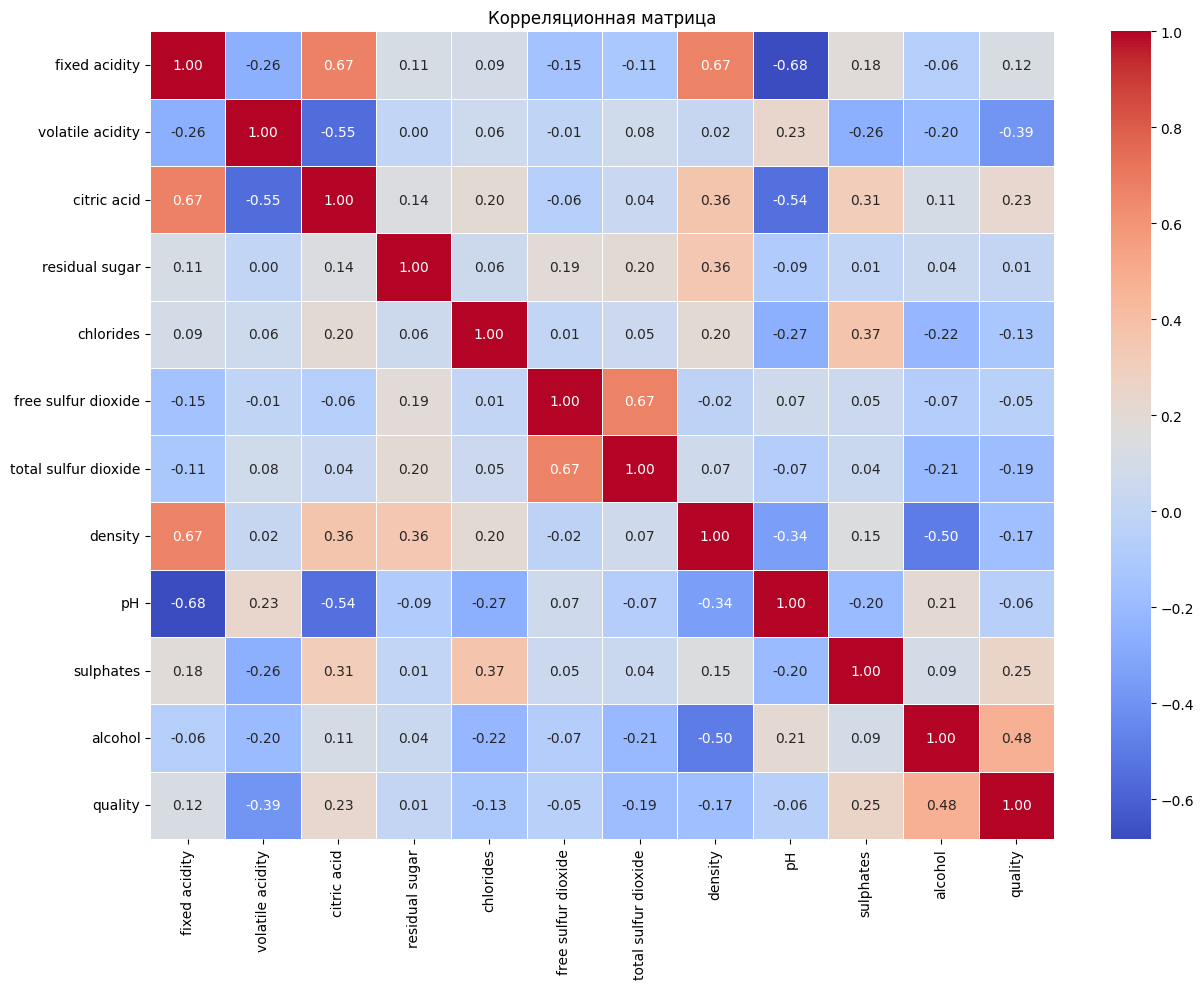

In [9]:

plt.figure(figsize=(13, 10))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()


Три наиболее коррелирующие пары:
fixed acidity  pH             0.682978
               citric acid    0.671703
               density        0.668047
dtype: float64


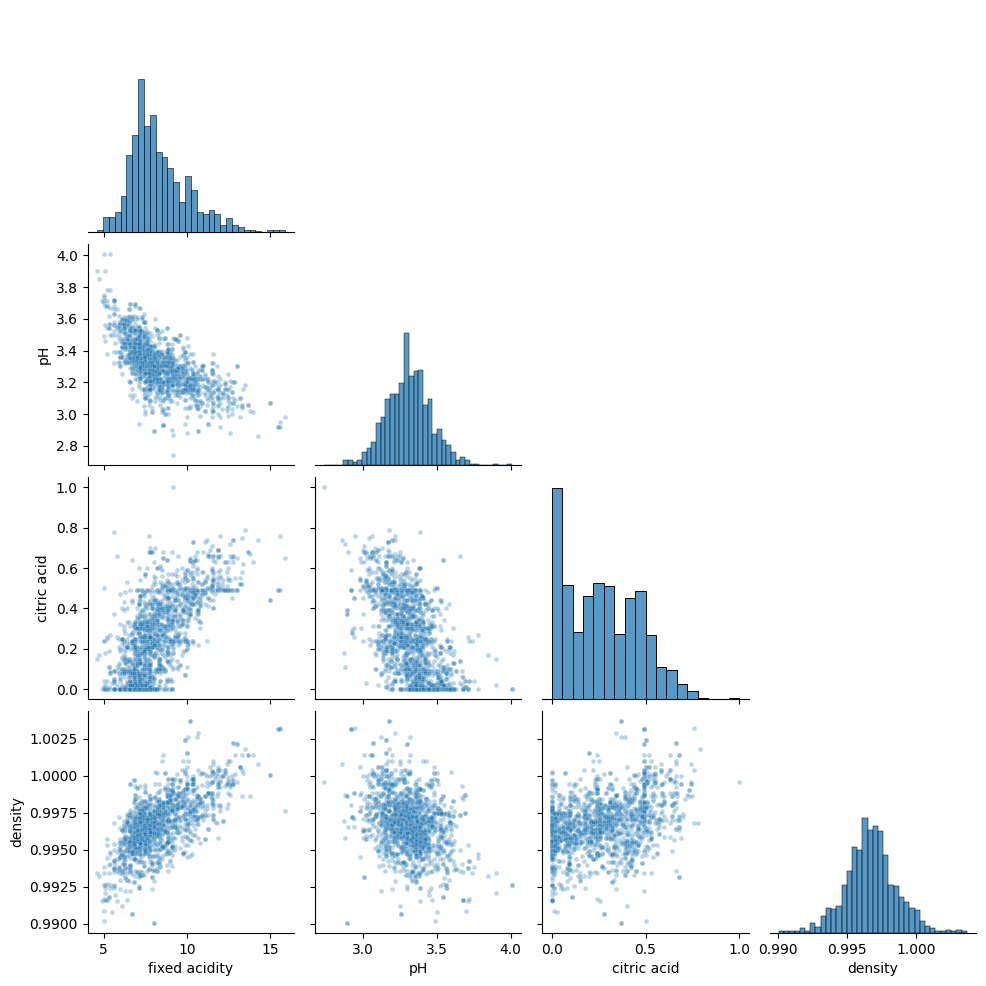

In [10]:

corr_features = df[numeric_features].corr().abs()

upper = corr_features.where(
    np.triu(
        np.ones(corr_features.shape),
        k=1
    ).astype(bool)
)

top_pairs = upper.stack().sort_values(ascending=False).head(3)

print("Три наиболее коррелирующие пары:")
print(top_pairs)

selected = list(dict.fromkeys(
    feature
    for pair in top_pairs.index
    for feature in pair
))

sns.pairplot(
    df[selected],
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 12}
)

plt.show()


,Количество,Процент
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


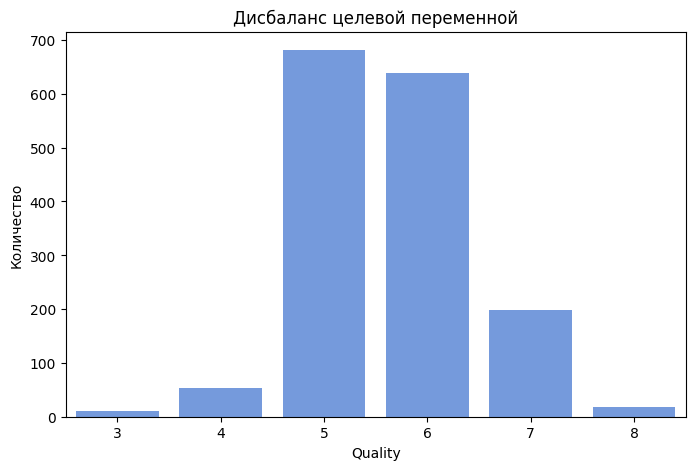

Самая частая категория: 5
Самая редкая категория: 3


In [11]:

target_counts = df["quality"].value_counts().sort_index()

target_percent = (
    df["quality"].value_counts(normalize=True)
    .sort_index() * 100
)

result = pd.DataFrame({
    "Количество": target_counts,
    "Процент": target_percent.round(2)
})

display(result)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=target_counts.index,
    y=target_counts.values,
    color="cornflowerblue"
)

plt.title("Дисбаланс целевой переменной")
plt.xlabel("Quality")
plt.ylabel("Количество")
plt.show()

print("Самая частая категория:", target_counts.idxmax())
print("Самая редкая категория:", target_counts.idxmin())


# Практическая работа №2
## Полный разведочный анализ данных (EDA)

**Вариант:** B  
**Датасет:** Wine Quality (Red Wine)  
**Источник:** UCI Machine Learning Repository

### Отчёт

1. **Общий осмотр данных.** Датасет содержит 1599 строк и 12 столбцов. В нём представлены 11 числовых характеристик и целевая переменная quality. Пропущенные значения отсутствуют.

2. **Повторяющиеся записи.** Обнаружено 240 полностью повторяющихся строк. На следующем занятии необходимо проверить природу повторов и решить, следует ли их удалять.

3. **Распределение числовых признаков.** Гистограммы показывают, что распределения некоторых признаков несимметричны. В дальнейшем можно рассмотреть преобразование сильно скошенных признаков.

4. **Выбросы.** Анализ с помощью boxplot и межквартильного размаха выявил потенциальные выбросы. Перед обработкой необходимо проверить, являются ли они ошибками или допустимыми наблюдениями.

5. **Категориальные признаки.** Оценки качества 5 и 6 встречаются чаще остальных. Категории 3, 4 и 8 являются редкими при пороге 5%. На следующем этапе следует учитывать это при подготовке данных.

6. **Корреляция признаков.** Корреляционная матрица выявляет связи между числовыми характеристиками. Перед обучением модели нужно проверить, не содержат ли сильно коррелирующие признаки избыточную информацию.

7. **Дисбаланс и дальнейшая обработка.** Целевая переменная quality распределена неравномерно. Для будущей классификации рекомендуется использовать стратифицированное разделение данных и подходящие метрики, например macro F1-score. Также планируется изучить необходимость масштабирования признаков.

### Заключение

В ходе практической работы проведён полный разведочный анализ датасета. Изучены структура данных, распределения, выбросы, частоты категорий, корреляции и дисбаланс целевой переменной. Результаты помогут подготовить данные к дальнейшему моделированию.

,Количество,Процент
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


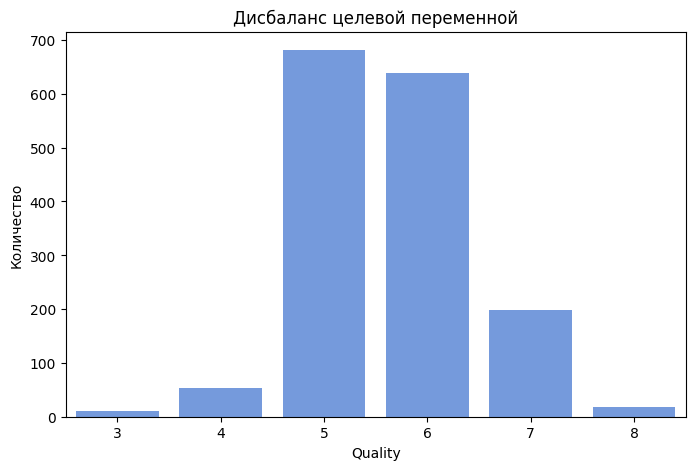

Самая частая категория: 5
Самая редкая категория: 3


In [12]:

target_counts = df["quality"].value_counts().sort_index()

target_percent = (
    df["quality"].value_counts(normalize=True)
    .sort_index() * 100
)

result = pd.DataFrame({
    "Количество": target_counts,
    "Процент": target_percent.round(2)
})

display(result)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=target_counts.index,
    y=target_counts.values,
    color="cornflowerblue"
)

plt.title("Дисбаланс целевой переменной")
plt.xlabel("Quality")
plt.ylabel("Количество")
plt.show()

print("Самая частая категория:", target_counts.idxmax())
print("Самая редкая категория:", target_counts.idxmin())


# Практическая работа №2
## Полный разведочный анализ данных (EDA)

**Вариант:** B  
**Датасет:** Wine Quality (Red Wine)  
**Источник:** UCI Machine Learning Repository

### Отчёт

1. **Общий осмотр данных.** Датасет содержит 1599 строк и 12 столбцов. В нём представлены 11 числовых характеристик и целевая переменная quality. Пропущенные значения отсутствуют.

2. **Повторяющиеся записи.** Обнаружено 240 полностью повторяющихся строк. На следующем занятии необходимо проверить природу повторов и решить, следует ли их удалять.

3. **Распределение числовых признаков.** Гистограммы показывают, что распределения некоторых признаков несимметричны. В дальнейшем можно рассмотреть преобразование сильно скошенных признаков.

4. **Выбросы.** Анализ с помощью boxplot и межквартильного размаха выявил потенциальные выбросы. Перед обработкой необходимо проверить, являются ли они ошибками или допустимыми наблюдениями.

5. **Категориальные признаки.** Оценки качества 5 и 6 встречаются чаще остальных. Категории 3, 4 и 8 являются редкими при пороге 5%. На следующем этапе следует учитывать это при подготовке данных.

6. **Корреляция признаков.** Корреляционная матрица выявляет связи между числовыми характеристиками. Перед обучением модели нужно проверить, не содержат ли сильно коррелирующие признаки избыточную информацию.

7. **Дисбаланс и дальнейшая обработка.** Целевая переменная quality распределена неравномерно. Для будущей классификации рекомендуется использовать стратифицированное разделение данных и подходящие метрики, например macro F1-score. Также планируется изучить необходимость масштабирования признаков.

### Заключение

В ходе практической работы проведён полный разведочный анализ датасета. Изучены структура данных, распределения, выбросы, частоты категорий, корреляции и дисбаланс целевой переменной. Результаты помогут подготовить данные к дальнейшему моделированию.

In [13]:

from google.colab import files

# Сохраняем датасет
df.to_csv("winequality-red.csv", index=False)

# Сохраняем версии библиотек
import importlib.metadata as metadata

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn"
]

with open("requirements.txt", "w") as f:
    for package in packages:
        f.write(f"{package}=={metadata.version(package)}\n")

print("Файлы подготовлены!")

files.download("winequality-red.csv")
files.download("requirements.txt")


Файлы подготовлены!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>